# Phase 4c— Gemma Robustness & Validity Checks

Robustness notebook for the **Gemma-2-2B-IT** cross-model validation.

Expected input from Phase 4:

- 76 usable pivots
- 13 corrections
- 63 hallucination pivots
- 625 features

Checks included:

1. baseline instance-level and prompt-grouped CV
2. repeated-seed stability
3. prompt-bootstrap confidence intervals
4. classifier AUC permutation tests
5. PCA and SelectKBest robustness
6. best-single-feature descriptive screening
7. coefficient stability
8. prompt-aware H4 permutation
9. leave-one-correction-prompt-out influence
10. cross-domain robustness

Qwen-only checks involving n=75 vs. n=127, a disjoint follow-up sample, and Qwen reviewer-label alternatives are intentionally omitted.

## 1. Imports and paths

In [16]:
import os, json
from pathlib import Path
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, f1_score, roc_auc_score, average_precision_score
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

np.random.seed(42)


def find_unique_file(filename):
    candidates = []
    working = Path('/kaggle/working/pivot_research_gemma') / filename
    if working.exists():
        candidates.append(working)
    for root, _, files in os.walk('/kaggle/input'):
        if filename in files:
            candidates.append(Path(root) / filename)
    candidates = sorted(set(candidates))
    print(f'Candidates for {filename}:')
    for i, p in enumerate(candidates):
        print(f'  [{i}] {p}')
    if not candidates:
        raise FileNotFoundError(f'{filename} not found.')
    if len(candidates) > 1:
        raise RuntimeError(f'Multiple copies of {filename} found. Set FEATURES_PATH manually.')
    return candidates[0]

FEATURES_PATH = find_unique_file('phase4_gemma_features.npz')
OUTPUT_DIR = Path('/kaggle/working/pivot_research_gemma')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_PATH = OUTPUT_DIR / 'phase4c_gemma_robustness_results.json'
FIGURE_PATH = OUTPUT_DIR / 'phase4c_gemma_robustness_summary.png'

print('\nUsing:', FEATURES_PATH)
print('Output:', OUTPUT_DIR)

Candidates for phase4_gemma_features.npz:
  [0] /kaggle/input/notebooks/gunjalgupta/phase-4a-gemma/pivot_research_gemma/phase4_gemma_features.npz

Using: /kaggle/input/notebooks/gunjalgupta/phase-4a-gemma/pivot_research_gemma/phase4_gemma_features.npz
Output: /kaggle/working/pivot_research_gemma


## 2. Load and verify features

In [17]:
with np.load(FEATURES_PATH, allow_pickle=False) as d:
    X = d['X'].astype(np.float64)
    y = d['y'].astype(int)
    prompt_ids = d['prompt_ids'].astype(str)
    categories = d['categories'].astype(str)
    h1 = d['h1'].astype(np.float64)
    h2 = d['h2'].astype(np.float64)
    h3 = d['h3'].astype(np.float64)
    h4 = d['h4'].astype(np.float64)

n_records, n_features = X.shape
print('X:', X.shape)
print('Labels:', dict(Counter(y)))
print('Prompts:', len(np.unique(prompt_ids)))
print('Categories:', dict(Counter(categories)))

assert X.shape == (76, 625)
assert int(y.sum()) == 13
assert int((y == 0).sum()) == 63
assert h1.shape == (76, 26, 8)
assert h2.shape == (76, 26, 8)
assert h3.shape == (76, 26, 8)
assert h4.shape == (76,)

print('\nCorrections by category:')
for cat in ('misdirection','math','logic'):
    m = categories == cat
    print(f'  {cat:<14} n={m.sum():<3} corrections={int(y[m].sum())}')

X: (76, 625)
Labels: {np.int64(0): 63, np.int64(1): 13}
Prompts: 47
Categories: {np.str_('misdirection'): 32, np.str_('math'): 35, np.str_('logic'): 9}

Corrections by category:
  misdirection   n=32  corrections=9
  math           n=35  corrections=3
  logic          n=9   corrections=1


## 3. Shared classifier helpers

In [18]:
def make_classifier(C=0.01):
    return LogisticRegression(class_weight='balanced', max_iter=3000, C=C, random_state=42)


def instance_cv(X, y, seed=42):
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    preds = np.zeros(len(y), dtype=int)
    probas = np.zeros(len(y), dtype=float)
    folds = []
    for fold, (tr, te) in enumerate(cv.split(X, y)):
        sc = StandardScaler()
        Xtr, Xte = sc.fit_transform(X[tr]), sc.transform(X[te])
        clf = make_classifier()
        clf.fit(Xtr, y[tr])
        preds[te] = clf.predict(Xte)
        probas[te] = clf.predict_proba(Xte)[:,1]
        folds.append({
            'fold': fold,
            'n_test': int(len(te)),
            'n_correction': int(y[te].sum()),
            'balanced_accuracy': float(balanced_accuracy_score(y[te], preds[te])),
            'roc_auc': float(roc_auc_score(y[te], probas[te])),
        })
    return {
        'preds': preds,
        'probas': probas,
        'auc': float(roc_auc_score(y, probas)),
        'balanced_accuracy': float(balanced_accuracy_score(y, preds)),
        'f1': float(f1_score(y, preds, zero_division=0)),
        'average_precision': float(average_precision_score(y, probas)),
        'folds': folds,
    }


def grouped_cv(X, y, groups, seed=42):
    cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
    preds = np.zeros(len(y), dtype=int)
    probas = np.zeros(len(y), dtype=float)
    folds = []
    for fold, (tr, te) in enumerate(cv.split(X, y, groups=groups)):
        if len(np.unique(y[tr])) < 2:
            raise RuntimeError(f'Seed {seed}, fold {fold}: training fold has one class.')
        sc = StandardScaler()
        Xtr, Xte = sc.fit_transform(X[tr]), sc.transform(X[te])
        clf = make_classifier()
        clf.fit(Xtr, y[tr])
        preds[te] = clf.predict(Xte)
        probas[te] = clf.predict_proba(Xte)[:,1]
        fold_auc = None if len(np.unique(y[te])) < 2 else float(roc_auc_score(y[te], probas[te]))
        folds.append({
            'fold': fold,
            'n_test': int(len(te)),
            'n_prompts': int(len(np.unique(groups[te]))),
            'n_correction': int(y[te].sum()),
            'balanced_accuracy': float(balanced_accuracy_score(y[te], preds[te])),
            'roc_auc': fold_auc,
        })
    return {
        'preds': preds,
        'probas': probas,
        'auc': float(roc_auc_score(y, probas)),
        'balanced_accuracy': float(balanced_accuracy_score(y, preds)),
        'f1': float(f1_score(y, preds, zero_division=0)),
        'average_precision': float(average_precision_score(y, probas)),
        'folds': folds,
    }

## 4. Baseline reproduction

In [19]:
base_instance = instance_cv(X, y, seed=42)
base_grouped = grouped_cv(X, y, prompt_ids, seed=42)

print('Instance CV:', {k: round(base_instance[k],3) for k in ('auc','balanced_accuracy','f1','average_precision')})
print('Grouped CV: ', {k: round(base_grouped[k],3) for k in ('auc','balanced_accuracy','f1','average_precision')})

print('\nGrouped fold composition:')
for f in base_grouped['folds']:
    print(f)

Instance CV: {'auc': 0.503, 'balanced_accuracy': 0.503, 'f1': 0.222, 'average_precision': 0.203}
Grouped CV:  {'auc': 0.614, 'balanced_accuracy': 0.549, 'f1': 0.278, 'average_precision': 0.266}

Grouped fold composition:
{'fold': 0, 'n_test': 11, 'n_prompts': 7, 'n_correction': 2, 'balanced_accuracy': 0.5833333333333333, 'roc_auc': 0.6666666666666666}
{'fold': 1, 'n_test': 15, 'n_prompts': 11, 'n_correction': 4, 'balanced_accuracy': 0.36363636363636365, 'roc_auc': 0.5227272727272727}
{'fold': 2, 'n_test': 16, 'n_prompts': 9, 'n_correction': 2, 'balanced_accuracy': 0.5, 'roc_auc': 0.6428571428571429}
{'fold': 3, 'n_test': 16, 'n_prompts': 10, 'n_correction': 2, 'balanced_accuracy': 0.6785714285714286, 'roc_auc': 0.6785714285714286}
{'fold': 4, 'n_test': 18, 'n_prompts': 10, 'n_correction': 3, 'balanced_accuracy': 0.7333333333333334, 'roc_auc': 0.6888888888888889}


## 5. Repeated-seed stability

In [20]:
SEEDS = list(range(30))
instance_seed_results = []
grouped_seed_results = []
grouped_failures = []

for seed in SEEDS:
    r = instance_cv(X, y, seed=seed)
    instance_seed_results.append({'seed':seed, 'auc':r['auc'], 'balanced_accuracy':r['balanced_accuracy']})
    try:
        r = grouped_cv(X, y, prompt_ids, seed=seed)
        grouped_seed_results.append({'seed':seed, 'auc':r['auc'], 'balanced_accuracy':r['balanced_accuracy']})
    except Exception as e:
        grouped_failures.append({'seed':seed, 'error':str(e)})

inst_auc = np.array([r['auc'] for r in instance_seed_results])
grp_auc = np.array([r['auc'] for r in grouped_seed_results])

paired = sorted(set(r['seed'] for r in instance_seed_results) & set(r['seed'] for r in grouped_seed_results))
inst_paired = np.array([next(r['auc'] for r in instance_seed_results if r['seed']==s) for s in paired])
grp_paired = np.array([next(r['auc'] for r in grouped_seed_results if r['seed']==s) for s in paired])

print(f'Instance AUC mean±SD: {inst_auc.mean():.3f}±{inst_auc.std():.3f}; range [{inst_auc.min():.3f}, {inst_auc.max():.3f}]')
print(f'Grouped AUC mean±SD:  {grp_auc.mean():.3f}±{grp_auc.std():.3f}; range [{grp_auc.min():.3f}, {grp_auc.max():.3f}]')
print(f'Grouped failures: {len(grouped_failures)}/{len(SEEDS)}')
print(f'Grouped > instance in {(grp_paired > inst_paired).mean():.1%} of paired seeds')

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


Instance AUC mean±SD: 0.599±0.041; range [0.519, 0.674]
Grouped AUC mean±SD:  0.592±0.034; range [0.525, 0.658]
Grouped failures: 0/30
Grouped > instance in 50.0% of paired seeds


## 6. Prompt-bootstrap AUC confidence intervals

In [21]:
def prompt_bootstrap_auc(y, probas, prompt_ids, n_boot=5000, seed=42):
    rng = np.random.default_rng(seed)
    prompts = np.array(sorted(np.unique(prompt_ids)))
    values = []
    for _ in range(n_boot):
        sampled = rng.choice(prompts, size=len(prompts), replace=True)
        idx = np.concatenate([np.where(prompt_ids == p)[0] for p in sampled])
        if len(np.unique(y[idx])) < 2:
            continue
        values.append(roc_auc_score(y[idx], probas[idx]))
    values = np.asarray(values)
    return {
        'values': values,
        'valid': int(len(values)),
        'requested': int(n_boot),
        'ci_low': float(np.percentile(values,2.5)),
        'ci_high': float(np.percentile(values,97.5)),
        'median': float(np.median(values)),
    }

boot_instance = prompt_bootstrap_auc(y, base_instance['probas'], prompt_ids)
boot_grouped = prompt_bootstrap_auc(y, base_grouped['probas'], prompt_ids)

print(f"Instance AUC={base_instance['auc']:.3f}, 95% CI [{boot_instance['ci_low']:.3f}, {boot_instance['ci_high']:.3f}] ({boot_instance['valid']}/{boot_instance['requested']} valid)")
print(f"Grouped  AUC={base_grouped['auc']:.3f}, 95% CI [{boot_grouped['ci_low']:.3f}, {boot_grouped['ci_high']:.3f}] ({boot_grouped['valid']}/{boot_grouped['requested']} valid)")

Instance AUC=0.503, 95% CI [0.317, 0.681] (5000/5000 valid)
Grouped  AUC=0.614, 95% CI [0.447, 0.774] (5000/5000 valid)


## 7. Classifier AUC permutation tests

In [22]:
def within_prompt_permute(y, prompt_ids, rng):
    yp = y.copy()
    for p in np.unique(prompt_ids):
        idx = np.where(prompt_ids == p)[0]
        if len(idx) > 1:
            yp[idx] = rng.permutation(yp[idx])
    return yp


def classifier_permutation(mode, observed_auc, n_perm=250, seed=42):
    rng = np.random.default_rng(seed)
    null = []
    failures = 0
    for _ in range(n_perm):
        try:
            if mode == 'instance':
                yp = rng.permutation(y)
                null.append(instance_cv(X, yp, seed=42)['auc'])
            elif mode == 'grouped_within_prompt':
                yp = within_prompt_permute(y, prompt_ids, rng)
                null.append(grouped_cv(X, yp, prompt_ids, seed=42)['auc'])
            else:
                raise ValueError(mode)
        except Exception:
            failures += 1
    null = np.asarray(null)
    p = (1 + np.sum(null >= observed_auc)) / (len(null) + 1)
    return {'values':null, 'p_value':float(p), 'valid':int(len(null)), 'failures':int(failures), 'null_mean':float(null.mean()), 'null_sd':float(null.std())}

N_PERM = 250
perm_instance = classifier_permutation('instance', base_instance['auc'], N_PERM)
perm_grouped = classifier_permutation('grouped_within_prompt', base_grouped['auc'], N_PERM)

print(f"Instance: observed={base_instance['auc']:.3f}, null={perm_instance['null_mean']:.3f}±{perm_instance['null_sd']:.3f}, p={perm_instance['p_value']:.4f}")
print(f"Grouped:  observed={base_grouped['auc']:.3f}, null={perm_grouped['null_mean']:.3f}±{perm_grouped['null_sd']:.3f}, p={perm_grouped['p_value']:.4f}")

Instance: observed=0.503, null=0.476±0.117, p=0.3904
Grouped:  observed=0.614, null=0.610±0.067, p=0.4582


## 8. PCA and SelectKBest robustness

In [23]:
def evaluate_pipeline(pipe, groups=None):
    scoring = {'balanced_accuracy':'balanced_accuracy', 'roc_auc':'roc_auc'}
    if groups is None:
        cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
        scores = cross_validate(pipe, X, y, cv=cv, scoring=scoring, error_score=np.nan)
    else:
        cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
        scores = cross_validate(pipe, X, y, groups=groups, cv=cv, scoring=scoring, error_score=np.nan)
    return {
        'balanced_accuracy_mean': float(np.nanmean(scores['test_balanced_accuracy'])),
        'balanced_accuracy_sd': float(np.nanstd(scores['test_balanced_accuracy'])),
        'roc_auc_mean': float(np.nanmean(scores['test_roc_auc'])),
        'roc_auc_sd': float(np.nanstd(scores['test_roc_auc'])),
        'valid_auc_folds': int(np.isfinite(scores['test_roc_auc']).sum()),
    }

dim_results = {'instance':{}, 'grouped':{}}

for n_comp in [5,10,20,30,40]:
    pipe = Pipeline([
        ('scale', StandardScaler()),
        ('pca', PCA(n_components=n_comp, random_state=42)),
        ('clf', LogisticRegression(class_weight='balanced', max_iter=3000, C=0.1, random_state=42)),
    ])
    key = f'PCA-{n_comp}'
    dim_results['instance'][key] = evaluate_pipeline(pipe)
    dim_results['grouped'][key] = evaluate_pipeline(pipe, prompt_ids)
    print(f"{key:<8} instance AUC={dim_results['instance'][key]['roc_auc_mean']:.3f} | grouped AUC={dim_results['grouped'][key]['roc_auc_mean']:.3f}")

for k in [5,10,20,50,100]:
    pipe = Pipeline([
        ('scale', StandardScaler()),
        ('select', SelectKBest(f_classif, k=k)),
        ('clf', LogisticRegression(class_weight='balanced', max_iter=3000, C=0.1, random_state=42)),
    ])
    key = f'SelectKBest-{k}'
    dim_results['instance'][key] = evaluate_pipeline(pipe)
    dim_results['grouped'][key] = evaluate_pipeline(pipe, prompt_ids)
    print(f"{key:<16} instance AUC={dim_results['instance'][key]['roc_auc_mean']:.3f} | grouped AUC={dim_results['grouped'][key]['roc_auc_mean']:.3f}")

PCA-5    instance AUC=0.434 | grouped AUC=0.624
PCA-10   instance AUC=0.496 | grouped AUC=0.716
PCA-20   instance AUC=0.535 | grouped AUC=0.637
PCA-30   instance AUC=0.469 | grouped AUC=0.606
PCA-40   instance AUC=0.447 | grouped AUC=0.573
SelectKBest-5    instance AUC=0.474 | grouped AUC=0.525
SelectKBest-10   instance AUC=0.488 | grouped AUC=0.549
SelectKBest-20   instance AUC=0.467 | grouped AUC=0.629
SelectKBest-50   instance AUC=0.474 | grouped AUC=0.587
SelectKBest-100  instance AUC=0.500 | grouped AUC=0.618


## 9. Best single-feature AUC (descriptive only)

In [24]:
def feature_block(i):
    if i < 208: return 'H1'
    if i < 416: return 'H2'
    if i < 624: return 'H3'
    return 'H4'

single_aucs = []
for i in range(X.shape[1]):
    auc = roc_auc_score(y, X[:,i])
    single_aucs.append(max(auc, 1-auc))
single_aucs = np.asarray(single_aucs)
best_idx = int(np.argmax(single_aucs))
print(f'Best oriented single-feature AUC: {single_aucs[best_idx]:.3f}')
print(f'Mean oriented single-feature AUC: {single_aucs.mean():.3f}')
print(f'Best feature: index={best_idx}, block={feature_block(best_idx)}')
print('Descriptive only: the maximum is selected on the same data and is strongly selection-biased.')

Best oriented single-feature AUC: 0.777
Mean oriented single-feature AUC: 0.614
Best feature: index=465, block=H3
Descriptive only: the maximum is selected on the same data and is strongly selection-biased.


## 10. Coefficient stability

In [25]:
def coefficient_stability(groups=None):
    if groups is None:
        cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
        splits = cv.split(X, y)
    else:
        cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
        splits = cv.split(X, y, groups=groups)
    coefs = []
    for tr, _ in splits:
        sc = StandardScaler()
        Xtr = sc.fit_transform(X[tr])
        clf = make_classifier()
        clf.fit(Xtr, y[tr])
        coefs.append(clf.coef_[0].copy())
    coefs = np.asarray(coefs)
    cm = np.corrcoef(coefs)
    pairs = np.array([cm[i,j] for i in range(len(coefs)) for j in range(i+1,len(coefs))])
    signs = np.sign(coefs)
    unanimous = np.all(signs == signs[0], axis=0)
    mean_abs = np.abs(coefs).mean(axis=0)
    stable_strong = unanimous & (mean_abs > np.percentile(mean_abs,95))
    idx = np.where(stable_strong)[0]
    counts = Counter(feature_block(int(i)) for i in idx)
    return {
        'mean_pairwise_correlation': float(pairs.mean()),
        'pairwise_correlation_sd': float(pairs.std()),
        'unanimous_sign_count': int(unanimous.sum()),
        'unanimous_sign_fraction': float(unanimous.mean()),
        'stable_strong_count': int(stable_strong.sum()),
        'stable_strong_by_block': {b:int(counts.get(b,0)) for b in ('H1','H2','H3','H4')},
    }

coef_instance = coefficient_stability()
coef_grouped = coefficient_stability(prompt_ids)
print('Instance folds:', coef_instance)
print('Grouped folds: ', coef_grouped)

Instance folds: {'mean_pairwise_correlation': 0.7030084148821301, 'pairwise_correlation_sd': 0.049298616048430326, 'unanimous_sign_count': 355, 'unanimous_sign_fraction': 0.568, 'stable_strong_count': 31, 'stable_strong_by_block': {'H1': 0, 'H2': 12, 'H3': 19, 'H4': 0}}
Grouped folds:  {'mean_pairwise_correlation': 0.7300266950786525, 'pairwise_correlation_sd': 0.07653627619037018, 'unanimous_sign_count': 346, 'unanimous_sign_fraction': 0.5536, 'stable_strong_count': 32, 'stable_strong_by_block': {'H1': 0, 'H2': 12, 'H3': 20, 'H4': 0}}


## 11. Prompt-aware H4 permutation

In [26]:
def h4_prompt_permutation(n_perm=10000, seed=42):
    rng = np.random.default_rng(seed)
    observed = h4[y==1].mean() - h4[y==0].mean()
    mixed = [p for p in np.unique(prompt_ids) if len(np.unique(y[prompt_ids==p])) > 1]
    null = np.zeros(n_perm)
    for i in range(n_perm):
        yp = within_prompt_permute(y, prompt_ids, rng)
        null[i] = h4[yp==1].mean() - h4[yp==0].mean()
    p = (1 + np.sum(np.abs(null) >= abs(observed))) / (n_perm + 1)
    return {'observed_correction_minus_hallucination':float(observed), 'p_value':float(p), 'mixed_prompt_count':int(len(mixed)), 'total_prompt_count':int(len(np.unique(prompt_ids)))}

h4_prompt = h4_prompt_permutation()
print(h4_prompt)

{'observed_correction_minus_hallucination': -0.011249608900375296, 'p_value': 0.5955404459554045, 'mixed_prompt_count': 6, 'total_prompt_count': 47}


## 12. Leave-one-correction-prompt-out influence

In [27]:
correction_prompts = sorted(np.unique(prompt_ids[y==1]))
leave_one = []
for held_out in correction_prompts:
    keep = prompt_ids != held_out
    try:
        r = grouped_cv(X[keep], y[keep], prompt_ids[keep], seed=42)
        leave_one.append({
            'held_out_prompt': held_out,
            'n_removed': int((~keep).sum()),
            'corrections_removed': int(y[~keep].sum()),
            'remaining_corrections': int(y[keep].sum()),
            'grouped_auc': float(r['auc']),
            'grouped_balanced_accuracy': float(r['balanced_accuracy']),
            'auc_change_from_full': float(r['auc'] - base_grouped['auc']),
            'status': 'ok',
        })
    except Exception as e:
        leave_one.append({'held_out_prompt':held_out, 'status':'failed', 'error':str(e)})

print(f"Full grouped AUC: {base_grouped['auc']:.3f}")
for r in leave_one:
    if r['status']=='ok':
        print(f"  remove {r['held_out_prompt']:<12} corr_removed={r['corrections_removed']:<2} AUC={r['grouped_auc']:.3f} change={r['auc_change_from_full']:+.3f}")
    else:
        print(r)

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


Full grouped AUC: 0.614
  remove logic_07     corr_removed=1  AUC=0.684 change=+0.070
  remove math_01      corr_removed=1  AUC=0.663 change=+0.049
  remove math_23      corr_removed=1  AUC=0.562 change=-0.052
  remove math_25      corr_removed=1  AUC=0.624 change=+0.010
  remove mis2_01      corr_removed=1  AUC=0.610 change=-0.004
  remove mis2_02      corr_removed=1  AUC=0.643 change=+0.029
  remove mis2_03      corr_removed=1  AUC=0.484 change=-0.130
  remove mis2_07      corr_removed=1  AUC=0.663 change=+0.049
  remove mis2_09      corr_removed=1  AUC=0.532 change=-0.082
  remove mis2_17      corr_removed=1  AUC=0.603 change=-0.011
  remove mis_06       corr_removed=1  AUC=0.594 change=-0.020
  remove mis_07       corr_removed=1  AUC=0.563 change=-0.051
  remove mis_08       corr_removed=1  AUC=0.597 change=-0.017


## 13. Cross-domain robustness

In [28]:
cross_domain = {}
for held_out in ('math','logic','misdirection'):
    te = categories == held_out
    tr = ~te
    result = {
        'n_train': int(tr.sum()), 'n_test': int(te.sum()),
        'n_correction_train': int(y[tr].sum()), 'n_correction_test': int(y[te].sum()),
    }
    if len(np.unique(y[tr])) < 2 or len(np.unique(y[te])) < 2:
        result['status'] = 'skipped_one_class'
    else:
        sc = StandardScaler()
        Xtr, Xte = sc.fit_transform(X[tr]), sc.transform(X[te])
        clf = make_classifier()
        clf.fit(Xtr, y[tr])
        pred = clf.predict(Xte)
        proba = clf.predict_proba(Xte)[:,1]
        result.update({
            'status':'ok',
            'balanced_accuracy': float(balanced_accuracy_score(y[te], pred)),
            'roc_auc': float(roc_auc_score(y[te], proba)),
        })
    cross_domain[held_out] = result

for domain, r in cross_domain.items():
    print(domain, r)

math {'n_train': 41, 'n_test': 35, 'n_correction_train': 10, 'n_correction_test': 3, 'status': 'ok', 'balanced_accuracy': 0.484375, 'roc_auc': 0.4583333333333333}
logic {'n_train': 67, 'n_test': 9, 'n_correction_train': 12, 'n_correction_test': 1, 'status': 'ok', 'balanced_accuracy': 0.3125, 'roc_auc': 0.375}
misdirection {'n_train': 44, 'n_test': 32, 'n_correction_train': 4, 'n_correction_test': 9, 'status': 'ok', 'balanced_accuracy': 0.3695652173913043, 'roc_auc': 0.4106280193236715}


## 14. Summary figure

/tmp/ipykernel_58/106070453.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[0,0].boxplot([inst_auc, grp_auc], labels=['Instance CV','Grouped CV'])


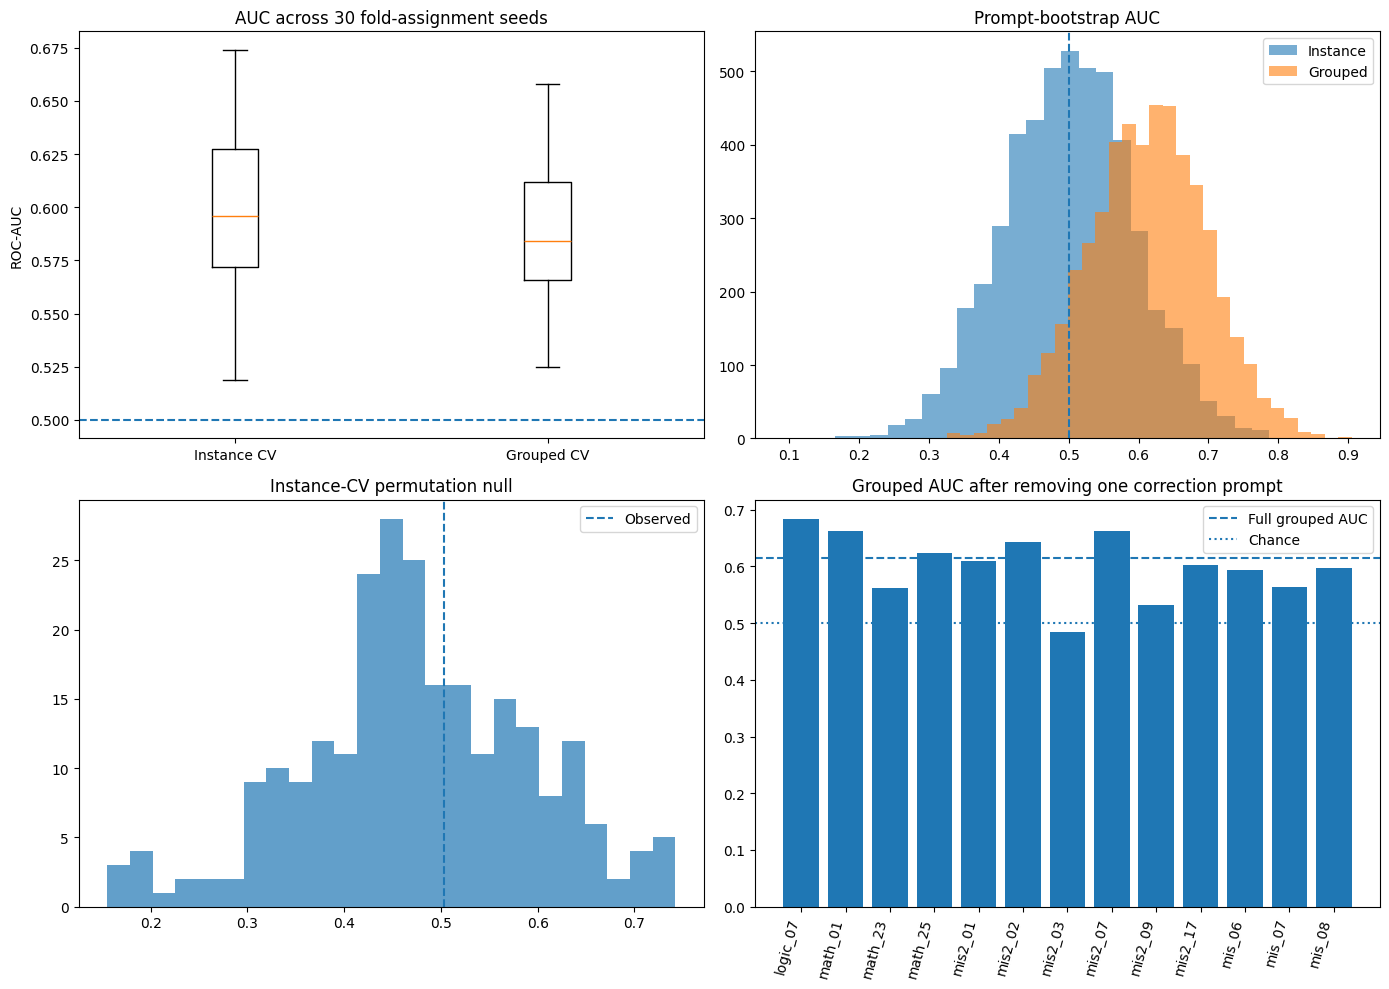

Saved: /kaggle/working/pivot_research_gemma/phase4c_gemma_robustness_summary.png


In [29]:
fig, axes = plt.subplots(2, 2, figsize=(14,10))

axes[0,0].boxplot([inst_auc, grp_auc], labels=['Instance CV','Grouped CV'])
axes[0,0].axhline(0.5, linestyle='--')
axes[0,0].set_title('AUC across 30 fold-assignment seeds')
axes[0,0].set_ylabel('ROC-AUC')

axes[0,1].hist(boot_instance['values'], bins=30, alpha=0.6, label='Instance')
axes[0,1].hist(boot_grouped['values'], bins=30, alpha=0.6, label='Grouped')
axes[0,1].axvline(0.5, linestyle='--')
axes[0,1].set_title('Prompt-bootstrap AUC')
axes[0,1].legend()

axes[1,0].hist(perm_instance['values'], bins=25, alpha=0.7)
axes[1,0].axvline(base_instance['auc'], linestyle='--', label='Observed')
axes[1,0].set_title('Instance-CV permutation null')
axes[1,0].legend()

successful = [r for r in leave_one if r['status']=='ok']
axes[1,1].bar(range(len(successful)), [r['grouped_auc'] for r in successful])
axes[1,1].axhline(base_grouped['auc'], linestyle='--', label='Full grouped AUC')
axes[1,1].axhline(0.5, linestyle=':', label='Chance')
axes[1,1].set_xticks(range(len(successful)))
axes[1,1].set_xticklabels([r['held_out_prompt'] for r in successful], rotation=75, ha='right')
axes[1,1].set_title('Grouped AUC after removing one correction prompt')
axes[1,1].legend()

plt.tight_layout()
plt.savefig(FIGURE_PATH, dpi=140, bbox_inches='tight')
plt.show()
print('Saved:', FIGURE_PATH)

## 15. Save results and print final summary

In [30]:
def without_values(d):
    return {k:v for k,v in d.items() if k != 'values'}

results = {
    'sample': {'n_records':int(n_records), 'n_corrections':int(y.sum()), 'n_hallucination_pivots':int((y==0).sum()), 'n_features':int(n_features), 'n_prompts':int(len(np.unique(prompt_ids)))},
    'baseline': {
        'instance': {k:v for k,v in base_instance.items() if k not in ('preds','probas')},
        'grouped': {k:v for k,v in base_grouped.items() if k not in ('preds','probas')},
    },
    'repeated_seeds': {
        'seeds':SEEDS,
        'instance_results':instance_seed_results,
        'grouped_results':grouped_seed_results,
        'grouped_failures':grouped_failures,
        'instance_auc_mean':float(inst_auc.mean()),
        'instance_auc_sd':float(inst_auc.std()),
        'grouped_auc_mean':float(grp_auc.mean()),
        'grouped_auc_sd':float(grp_auc.std()),
        'fraction_grouped_above_instance':float((grp_paired > inst_paired).mean()),
    },
    'prompt_bootstrap': {'instance':without_values(boot_instance), 'grouped':without_values(boot_grouped)},
    'classifier_permutation': {'n_requested':N_PERM, 'instance':without_values(perm_instance), 'grouped_within_prompt':without_values(perm_grouped)},
    'dimensionality_reduction':dim_results,
    'single_feature': {'best_oriented_auc':float(single_aucs[best_idx]), 'mean_oriented_auc':float(single_aucs.mean()), 'best_feature_index':best_idx, 'best_feature_block':feature_block(best_idx), 'note':'Descriptive only; selected on the same data.'},
    'coefficient_stability': {'instance_folds':coef_instance, 'grouped_folds':coef_grouped},
    'h4_prompt_aware':h4_prompt,
    'leave_one_correction_prompt_out':leave_one,
    'cross_domain':cross_domain,
}

with open(RESULTS_PATH,'w',encoding='utf-8') as f:
    json.dump(results,f,indent=2)

print('='*76)
print('GEMMA ROBUSTNESS SUMMARY')
print('='*76)
print(f"n={n_records} ({int(y.sum())} correction / {int((y==0).sum())} hallucination_pivot)")
print(f"Instance CV: AUC={base_instance['auc']:.3f} | BA={base_instance['balanced_accuracy']:.3f}")
print(f"Grouped CV:  AUC={base_grouped['auc']:.3f} | BA={base_grouped['balanced_accuracy']:.3f}")
print(f"Repeated-seed instance AUC: {inst_auc.mean():.3f}±{inst_auc.std():.3f}")
print(f"Repeated-seed grouped AUC:  {grp_auc.mean():.3f}±{grp_auc.std():.3f}")
print(f"Grouped > instance in {(grp_paired > inst_paired).mean():.1%} of paired seeds")
print(f"Instance bootstrap CI: [{boot_instance['ci_low']:.3f}, {boot_instance['ci_high']:.3f}]")
print(f"Grouped bootstrap CI:  [{boot_grouped['ci_low']:.3f}, {boot_grouped['ci_high']:.3f}]")
print(f"Instance permutation p={perm_instance['p_value']:.4f}")
print(f"Grouped within-prompt permutation p={perm_grouped['p_value']:.4f}")
print(f"Best single feature AUC={single_aucs[best_idx]:.3f} ({feature_block(best_idx)}; descriptive only)")
print(f"H4 prompt-aware p={h4_prompt['p_value']:.4f}")
print('\nFiles:')
print(' ', RESULTS_PATH)
print(' ', FIGURE_PATH)

GEMMA ROBUSTNESS SUMMARY
n=76 (13 correction / 63 hallucination_pivot)
Instance CV: AUC=0.503 | BA=0.503
Grouped CV:  AUC=0.614 | BA=0.549
Repeated-seed instance AUC: 0.599±0.041
Repeated-seed grouped AUC:  0.592±0.034
Grouped > instance in 50.0% of paired seeds
Instance bootstrap CI: [0.317, 0.681]
Grouped bootstrap CI:  [0.447, 0.774]
Instance permutation p=0.3904
Grouped within-prompt permutation p=0.4582
Best single feature AUC=0.777 (H3; descriptive only)
H4 prompt-aware p=0.5955

Files:
  /kaggle/working/pivot_research_gemma/phase4c_gemma_robustness_results.json
  /kaggle/working/pivot_research_gemma/phase4c_gemma_robustness_summary.png
